## Mass Test SANOS

In [ ]:


%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.utils.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries

from datetime import date
from quantdata.widb.timeseries import build_time_series, TimeSeriesDefinition, ExpiryFilter, RawDayFilter, OptionsFilter, DateRange, PoolConfig, table_of_time_series, MkArbFree
from quantdata.biz_calendar import next_business_day
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context
from IPython.display import display

def get_times_series(ticker):
    include_fields = {'pure_strike',
                      'pure_ask_price','pure_bid_price',
                      'tte_y','ask_vol','bid_vol','is_valid'}

    time_series_def = TimeSeriesDefinition(
        raw_day_filter = RawDayFilter(),
        expiry_filter = ExpiryFilter(),
        mk_arb_free = None,
        options_filter = OptionsFilter()
    )
    date_range = DateRange(start=date(2021, 1, 1), end=date(2025, 8, 1)) 
    pool_config = PoolConfig(num_workers=4, threading=False)
    verbose = Context.all
    samples = build_time_series(ticker, date_range, include_fields=include_fields, exclude_fields=None, time_series_def=time_series_def, pool_config=pool_config, verbose=verbose, override_cache_mode="on" )
    return samples

ticker = "SPX"
time_series = get_times_series(ticker)
verbose = Context.all
verbose.write(str(table_of_time_series(time_series)))
print("/done")

01:   Generating daily data for SPX time series from 2021-01-04 to 2021-01-08 excluding half days:
02:     Options filter: nopt=1000,bdte=756,nms=4.0,lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
02:     Raw Day filter: bid=0.011
02:     Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
02:     Pool config: workers 4p
01:   Generated daily data 5 dates for SPX from 2021-01-04 to 2021-01-08 excluding half days. Maximum number of options is 1000. This took 1.6s.
00: Aggregating data for ticker SPX for 5 business days from 2021-01-04 to 2021-01-08 excluding half days:
01:   Options filter: nopt=1000,bdte=756,nms=4.0,lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   Raw Day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
01:   Pool config: workers 4p
01:   Requested fields: ask_vol, bid_vol, is_valid, pure_ask_price, pure_bid_price, pure_strike and tte_y
00: Read the generated enriched data for SPX in the main process; this took 0.14s. 

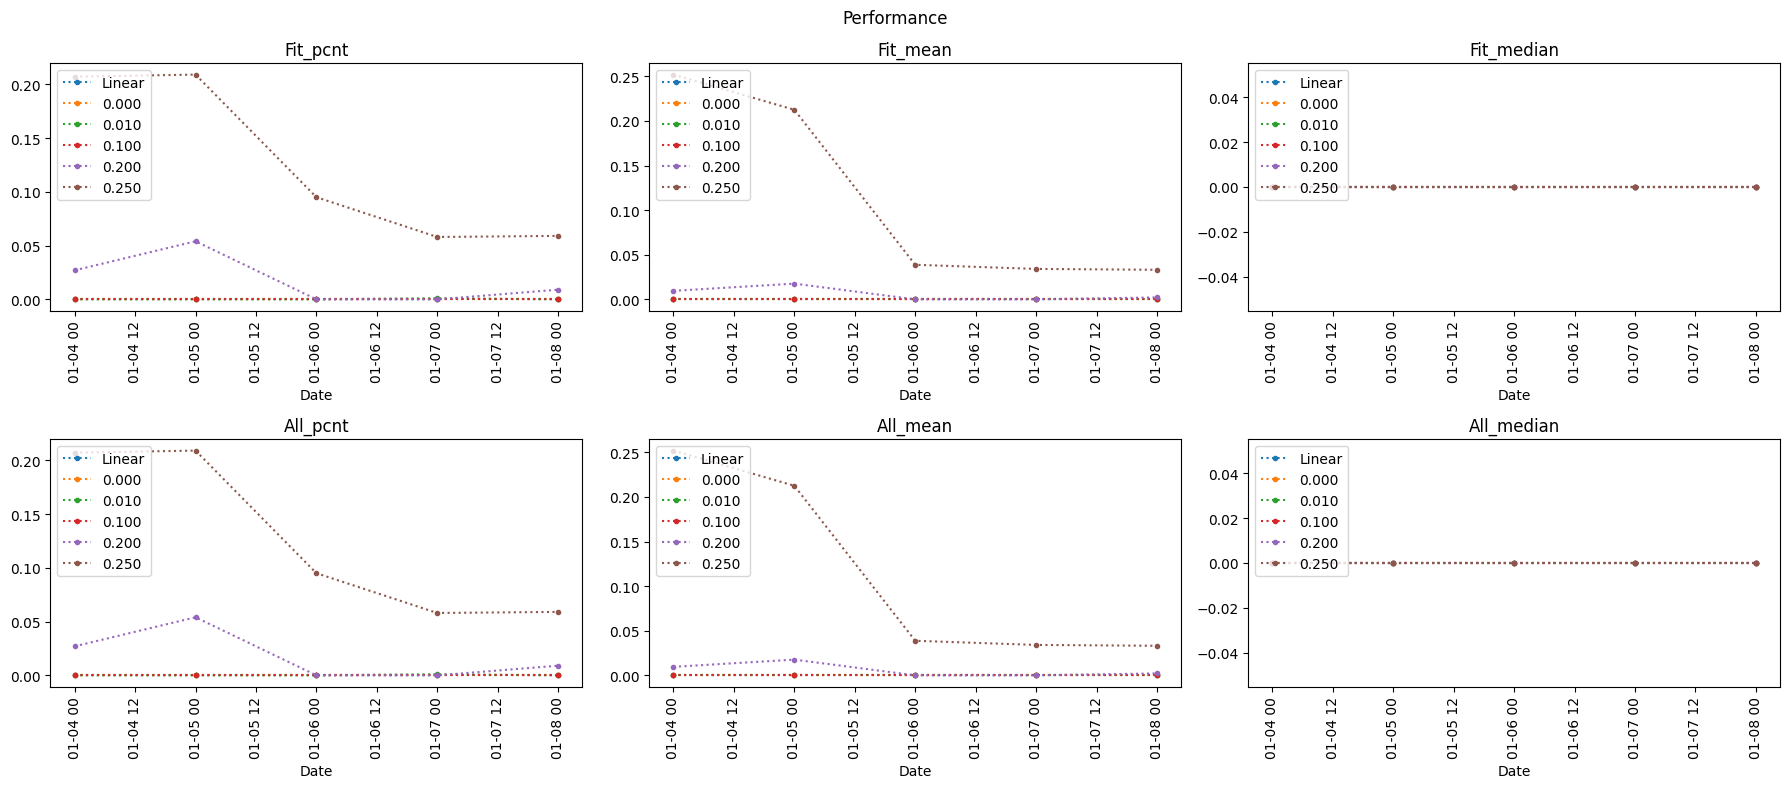

00: Expiry #0 2.0d: Generating extended strikes... using 24 extended strikes based on 22 market strikes.
00: Expiry #0 2.0d: Generating extended strikes... using 24 extended strikes based on 22 market strikes.
00: Expiry #0 2.0d: Soft linear no-arbitrage fit succeeded within bid/ask. This took 9.83ms.
00: Expiry #1 4.0d: Generating extended strikes... using 32 extended strikes based on 30 market strikes.
00: Expiry #1 4.0d: Soft linear no-arbitrage fit succeeded within bid/ask. This took 7.81ms.
00: Expiry #2 5.0d: Generating extended strikes... using 36 extended strikes based on 34 market strikes.
00: Expiry #2 5.0d: Soft linear no-arbitrage fit succeeded within bid/ask. This took 7.2ms.
00: Expiry #3 7.0d: Generating extended strikes... using 41 extended strikes based on 39 market strikes.
00: Expiry #3 7.0d: Soft linear no-arbitrage fit succeeded within bid/ask. This took 7.22ms.
00: Expiry #4 8.2d: Generating extended strikes... using 45 extended strikes based on 43 market strikes.

In [2]:
from cdxcore.jcpool import JCPool
from cdxcore.pretty import PrettyObject
import numpy as np
from prettytable import PrettyTable
from cdxcore.subdir import SubDir
from cdxcore.uniquehash import named_unique_filename48_8
from cdxcore.dynaplot import figure, color_tableau

smoothnesses = [None, 0.0, 0.01, 0.1, 0.2, 0.25 ]

_cache = SubDir("!/tmp/arbfree_cache")

@_cache.cache("0.1", uid = lambda ticker, d, smoothness: f"{ticker}/{named_unique_filename48_8(f'{d} {smoothness:4f}' if not smoothness is None else str(d),d,smoothness)}")
def fit_arb_free( ticker, d, smoothness, ddata ):
    expiries = ddata['expiries']
    bids     = ddata['bids']
    asks     = ddata['asks']
    strikes  = ddata['strikes']
    mk_af    = MkArbFree(smoothness=smoothness, surface_expiry_linear=True)
    af       = mk_af( expiries=expiries,
                      strikes=strikes,
                      bids=bids,
                      asks=asks,
                      verbose=Context.all  )

    # error on the strikes we think we can fit
    Taf      = len(af.expiries)
    af.errsX = []
    for t in range(Taf):
        masks_t = af.masks[t]
        fitX_t  = af.fitsX[t][masks_t]
        bids_t  = bids[t][masks_t]
        asks_t  = asks[t][masks_t]
        hs_t    = np.maximum( (asks_t - bids_t)/2., mk_af.min_half_spread )
        errX    = ( np.maximum( 0., fitX_t - asks_t ) + np.maximum( 0., bids_t - fitX_t )  ) / hs_t
        af.errsX.append( errX )
        del errX, hs_t, asks_t, bids_t, fitX_t, masks_t

    # errors on all strikes
    af.input_strikes  = strikes
    af.input_bids     = bids
    af.input_asks     = asks
    af.input_expiries = expiries
    af.input_fitsX    = []
    af.input_errsX    = []
    T = len(bids)

    for t in range(T):
        fitX_t = af.price( expiry=expiries[t], strikes=strikes[t], mode="surface" )
        bids_t = bids[t]
        asks_t = asks[t]
        hs_t   = np.maximum( (asks_t - bids_t)/2., mk_af.min_half_spread )
        errX = ( np.maximum( 0., fitX_t - asks_t ) + np.maximum( 0., bids_t - fitX_t )  ) / hs_t
        af.input_fitsX.append( fitX_t )
        af.input_errsX.append( errX )
        del fitX_t, hs_t, asks_t, bids_t, errX

    # stats
    errsX      = np.concatenate( af.errsX )
    inp_errsX  = np.concatenate( af.input_errsX )

    def stats(err):
        r = PrettyObject()
        r.err_cnt = np.sum(err>0.)
        r.total_cnt = len(err)
        r.pcnt = float(r.err_cnt) / float(max(1,r.total_cnt))
        r.mean = np.mean(err)
        r.median = np.median(err)
        r.mean_pos = np.mean(err[err>0.]) if np.any(err>0) else 0.
        r.median_pos = np.median(err[err>0]) if np.any(err>0) else 0.
        r.max = np.max(err)
        return r

    af.stats = stats(errsX)
    af.input_stats = stats(inp_errsX)
    af.ticker = ticker
    af.date = d

    return af        

def block_data(time_series, idd ):

    is_valid_t = time_series['pure_strike'][idd,:].astype(bool, copy=False)
    strikes_t  = time_series['pure_strike'][idd,:][is_valid_t]
    ixs        = np.argsort(strikes_t)
    strikes_t  = strikes_t[ixs]
    bids_t     = time_series['pure_bid_price'][idd,:][is_valid_t][ixs]
    asks_t     = time_series['pure_ask_price'][idd,:][is_valid_t][ixs]
    tte_yt     = time_series['tte_y'][idd,:][is_valid_t][ixs]
    del is_valid_t

    ddata = PrettyObject()
    ddata.expiries = []
    ddata.strikes = []
    ddata.asks = []
    ddata.bids = []

    uttys = np.unique(tte_yt)
    for utty in uttys:
        mask = tte_yt == utty
        if np.sum(mask) == 0:
            continue
        ddata.expiries.append(utty)
        ddata.strikes.append(np.asarray(strikes_t[mask]))
        ddata.asks.append(np.asarray(asks_t[mask]))
        ddata.bids.append(np.asarray(bids_t[mask]))

    return ddata

def mass_fit(ticker, time_series):
    pool = JCPool(num_workers=0, threading=True)

    results = {}

    dates   = time_series['dates']
    results = {}

    total   = len(smoothnesses) * len(dates)
    cnt     = 0

    perf_dates     = [ [] for _ in smoothnesses ]
    perf = PrettyObject()
    perf.fit_pcnt   = [ [] for _ in smoothnesses ]
    perf.fit_mean   = [ [] for _ in smoothnesses ]
    perf.fit_median = [ [] for _ in smoothnesses ]
    perf.all_pcnt   = [ [] for _ in smoothnesses ]
    perf.all_mean   = [ [] for _ in smoothnesses ]
    perf.all_median = [ [] for _ in smoothnesses ]

    with figure("Performance", row_size=4, col_size=6, columns=3) as fig:
        axs = { stat :  fig.add_subplot(stat[0].upper() + stat[1:]) for stat in perf }
        for ax in axs.values():
            ax.set_xlabel("Date")
            ax.tick_params(axis="x", labelrotation=90)   # vertical

        stores = [ fig.store() for _ in smoothnesses ]
        fig.render()

        for (ismth, d), af in pool.parallel( { (ismth, d) : pool.delayed(fit_arb_free)( ticker=ticker, d=d, smoothness=smth, ddata=block_data(time_series, idd), override_cache_mode="update" ) for ismth, smth in enumerate(smoothnesses) for idd, d in enumerate(dates) } ):
            cnt += 1
            results[(af.date,ismth)] = af

            perf_dates[ismth].append(af.date)
            perf.fit_pcnt[ismth].append(af.stats.pcnt)
            perf.fit_mean[ismth].append(af.stats.mean)
            perf.fit_median[ismth].append(af.stats.median)
            perf.all_pcnt[ismth].append(af.input_stats.pcnt)
            perf.all_mean[ismth].append(af.input_stats.mean)
            perf.all_median[ismth].append(af.input_stats.median)

            print(f"Progress: {cnt}/{total} ({(100.0*cnt)/float(total):.2f}%) - Date: {af.date}, Smoothness: {af.smoothness}, Fit mean: {af.stats.mean:.4g} [{af.stats.err_cnt}/{af.stats.total_cnt}], All mean: {af.input_stats.mean:.4g} [{af.input_stats.err_cnt}/{af.input_stats.total_cnt}]")

            perf_dates_i = np.array(perf_dates[ismth])
            ixs          = np.argsort(perf_dates_i)
            perf_dates_i = perf_dates_i[ixs]
            col          = color_tableau(ismth)
            stores[ismth].clear()

            for stat, values in perf.items():
                ax            = axs[stat]
                values        = np.array(values[ismth])[ixs]
                stores[ismth] += ax.plot( perf_dates_i, values, ".:", color=col, label=f"{af.smoothness:.3f}" if not af.smoothness is None else "Linear" )
                ax.legend(loc="upper left")
            fig.render()
    return results

results = mass_fit(ticker, time_series)



